# 04 · LightGBM et explicabilité avec SHAP

**LightGBM** construit des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents
(*gradient boosting*). Il utilise directement les 170 variables brutes et capte seul les relations non linéaires
et les interactions entre variables. Il est souvent plus performant qu'une scorecard… mais c'est une « boîte noire ».

**SHAP** permet d'ouvrir cette boîte noire : pour chaque client, il calcule la contribution de chaque variable à sa note de risque.

Le modèle est entraîné par `python -m credit_risk_scoring.lgbm` (environ 6 minutes) ; ce notebook le recharge.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import roc_curve

from credit_risk_scoring.config import FIGURES
from credit_risk_scoring.lgbm import MODEL_PATH as LGBM_PATH
from credit_risk_scoring.modeling import evaluate, load_features, split
from credit_risk_scoring.scorecard import MODEL_PATH as SCORECARD_PATH

sns.set_theme(style="whitegrid")
df = load_features()
X_train, X_test, y_train, y_test = split(df)
lgbm = joblib.load(LGBM_PATH)
scorecard = joblib.load(SCORECARD_PATH)

pd_lgbm = lgbm.predict_proba(X_test)
pd_sc = scorecard.predict_proba(X_test)
print(f"LightGBM : {lgbm.n_rounds} arbres, {len(lgbm.features)} variables")

LightGBM : 3043 arbres, 170 variables


## 1. Comparaison avec la scorecard

In [2]:
comparison = pd.DataFrame({
    f"Scorecard ({len(scorecard.variables)} variables)": evaluate(y_test, pd_sc),
    f"LightGBM ({len(lgbm.features)} variables)": evaluate(y_test, pd_lgbm),
}).T.round(3)
comparison

,AUC,Gini,KS
Scorecard (19 variables),0.757,0.515,0.390
LightGBM (170 variables),0.790,0.580,0.441


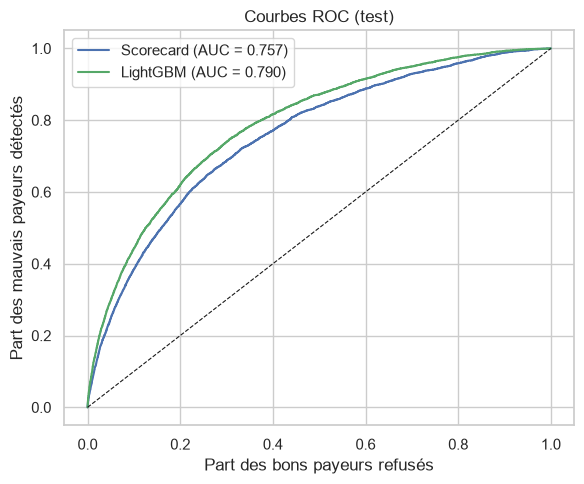

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p, color in [("Scorecard", pd_sc, "#4C72B0"), ("LightGBM", pd_lgbm, "#55A868")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC = {evaluate(y_test, p)['AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("Part des bons payeurs refusés"); ax.set_ylabel("Part des mauvais payeurs détectés")
ax.set_title("Courbes ROC (test)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "04_roc_comparaison.png", dpi=120); plt.show()

LightGBM gagne environ **6 points de Gini**. En crédit, c'est un écart important :
à taux d'acceptation égal, la banque accorde moins de crédits à des clients qui ne rembourseront pas.

### Attention au score sur le train

In [4]:
print(f"AUC train : {evaluate(y_train, lgbm.predict_proba(X_train))['AUC']:.3f}")
print(f"AUC validation croisée : {lgbm.cv_auc:.3f} ± {lgbm.cv_auc_std:.3f}")
print(f"AUC test : {evaluate(y_test, pd_lgbm)['AUC']:.3f}")

AUC train : 0.842
AUC validation croisée : 0.785 ± 0.005
AUC test : 0.790


L'AUC sur le train est bien plus élevée : les arbres ont en partie **mémorisé** les données d'entraînement.
C'est pourquoi on ne juge jamais un modèle sur le train. La **validation croisée** (5 découpages du train) donnait
une estimation honnête, confirmée ensuite par le test. C'est elle qui a fixé le nombre d'arbres (arrêt anticipé).

## 2. Quelles variables comptent ? (importance globale)

L'importance par **gain** mesure combien chaque variable a amélioré les arbres au total.

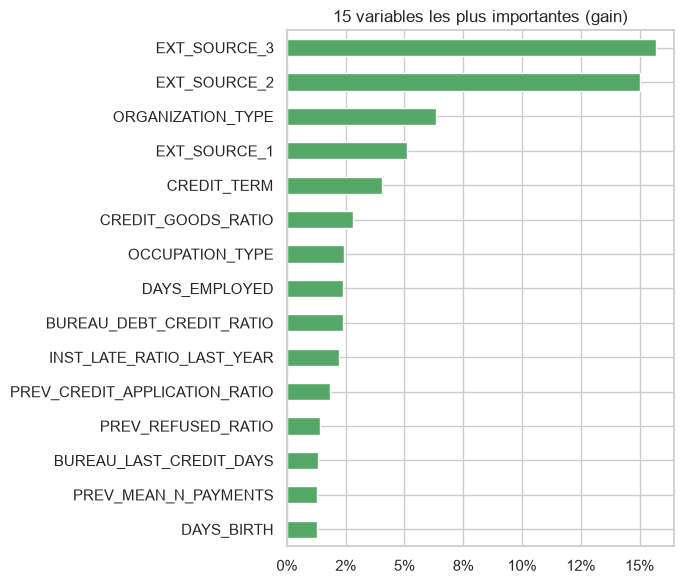

In [5]:
imp = lgbm.feature_importance().head(15)[::-1]
ax = imp.plot.barh(figsize=(7, 6), color="#55A868")
ax.set_title("15 variables les plus importantes (gain)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIGURES / "04_importance.png", dpi=120); plt.show()

On retrouve les mêmes variables que dans la scorecard : scores externes, type d'organisation, durée du crédit,
retards récents, endettement… Les deux modèles racontent la **même histoire**, ce qui est rassurant.

Mais cette importance ne dit pas **dans quel sens** une variable agit, ni pour **quel client**. C'est le rôle de SHAP.

## 3. SHAP : la contribution de chaque variable

Pour un client, SHAP répartit sa note de risque entre les variables :

$$\text{note du client} = \text{note moyenne} + \sum_{\text{variables}} \text{contribution SHAP}$$

- contribution **positive** : la variable **augmente** le risque de ce client ;
- contribution **négative** : elle le **diminue**.

Les notes sont en *log-odds* (l'échelle interne du modèle) : plus c'est haut, plus le risque est élevé.
On calcule SHAP sur 2 000 demandes du test (LightGBM le fait nativement avec `pred_contrib=True`).

In [6]:
sample = X_test.sample(2000, random_state=0)
contrib = lgbm.booster.predict(lgbm._prepare(sample), pred_contrib=True)

numeric_data = lgbm._prepare(sample).apply(lambda s: s.cat.codes.where(s.notna()) if s.dtype == "category" else s)
explanation = shap.Explanation(
    values=contrib[:, :-1],
    base_values=contrib[:, -1],
    data=numeric_data.to_numpy(dtype=float),
    display_data=sample.to_numpy(),
    feature_names=lgbm.features,
)

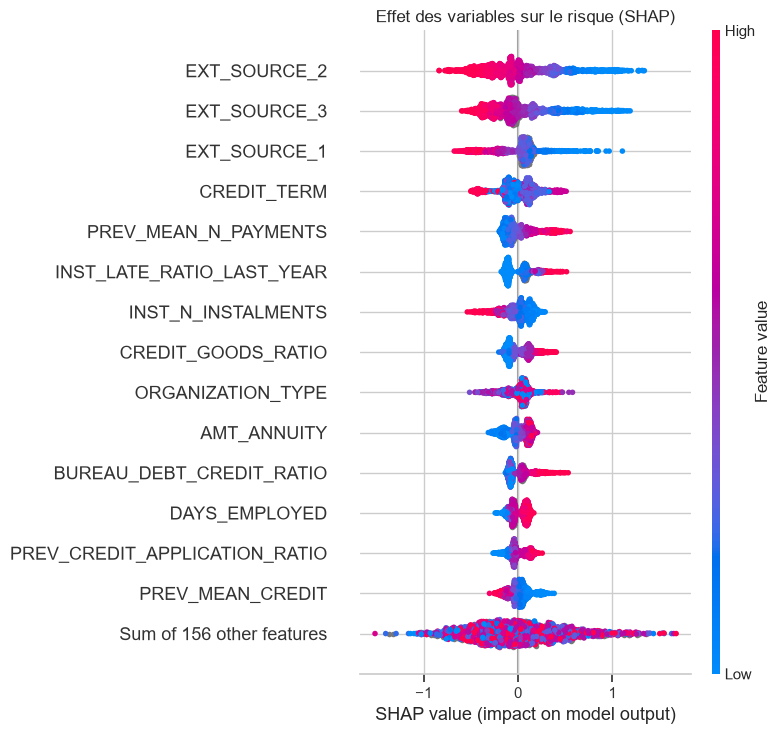

In [7]:
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title("Effet des variables sur le risque (SHAP)")
plt.tight_layout(); plt.savefig(FIGURES / "04_shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

**Comment lire ce graphique :** chaque point est un client. La position horizontale donne l'effet sur son risque,
la couleur donne la valeur de la variable (rouge = élevée, bleu = faible).

- `EXT_SOURCE_3`, `EXT_SOURCE_2` : les points **rouges** (scores élevés) sont **à gauche** → un bon score externe **réduit** le risque.
- `CREDIT_TERM` : effet non linéaire, comme vu en exploration.
- Les points gris sont des valeurs manquantes ou des catégories (métier, organisation).

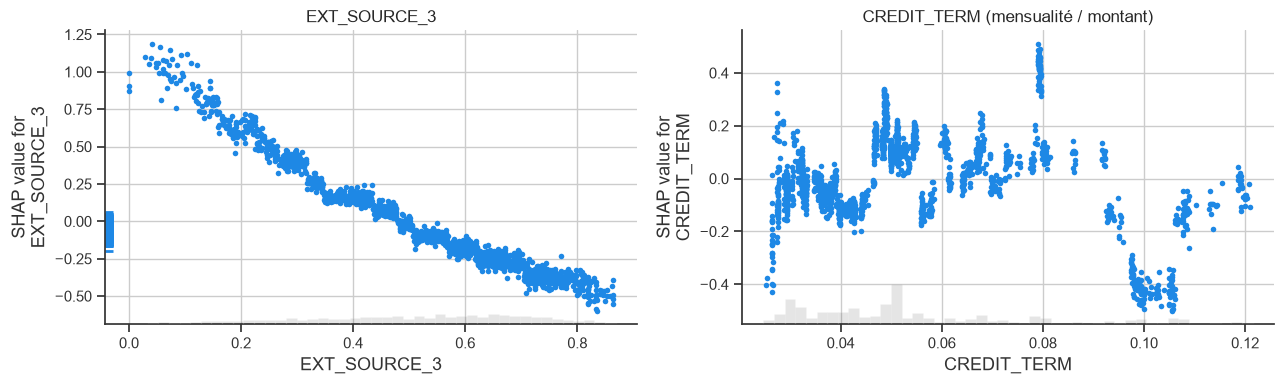

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
shap.plots.scatter(explanation[:, "EXT_SOURCE_3"], ax=axes[0], show=False)
shap.plots.scatter(explanation[:, "CREDIT_TERM"], ax=axes[1], show=False)
axes[0].set_title("EXT_SOURCE_3"); axes[1].set_title("CREDIT_TERM (mensualité / montant)")
plt.tight_layout(); plt.savefig(FIGURES / "04_shap_dependance.png", dpi=120); plt.show()

Ces graphiques de **dépendance** montrent la forme exacte de l'effet appris :
- `EXT_SOURCE_3` : le risque baisse régulièrement quand le score augmente ;
- `CREDIT_TERM` : les points forment des **paquets**, car les crédits ont des durées standard (la mensualité / montant
  prend donc quelques valeurs typiques). Le risque **n'évolue pas dans un seul sens** : certaines durées, comme autour
  de 0,10 (crédits courts), sont nettement moins risquées que leurs voisines. C'est la relation non monotone repérée
  dès l'analyse exploratoire, qu'une corrélation linéaire ne pouvait pas voir et que les arbres captent naturellement.

## 4. Expliquer une décision individuelle

C'est ce qu'exige la réglementation (RGPD, directive sur le crédit à la consommation) : un client refusé
doit pouvoir obtenir une **explication**. Comparons le client le plus risqué et le moins risqué de l'échantillon.

Client le plus risqué : probabilité de défaut 82.3%


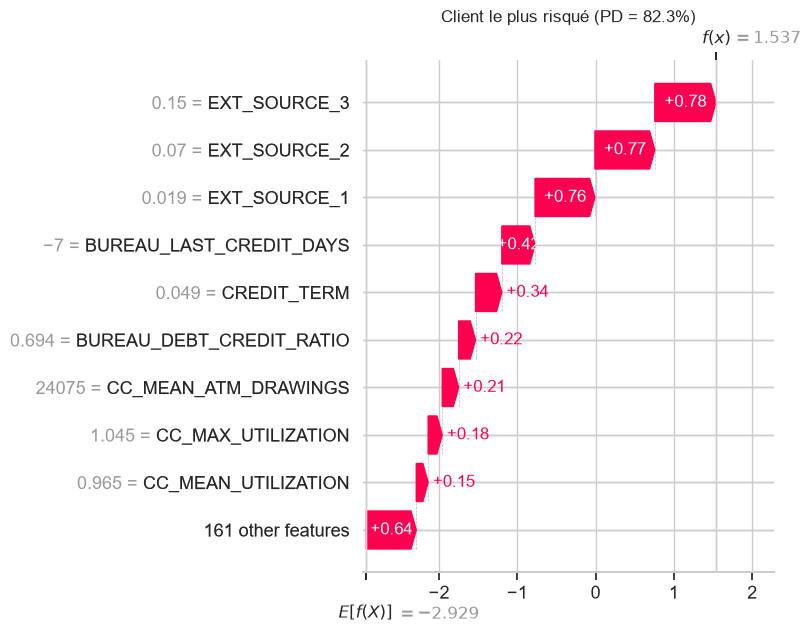

Client le moins risqué : probabilité de défaut 0.4%


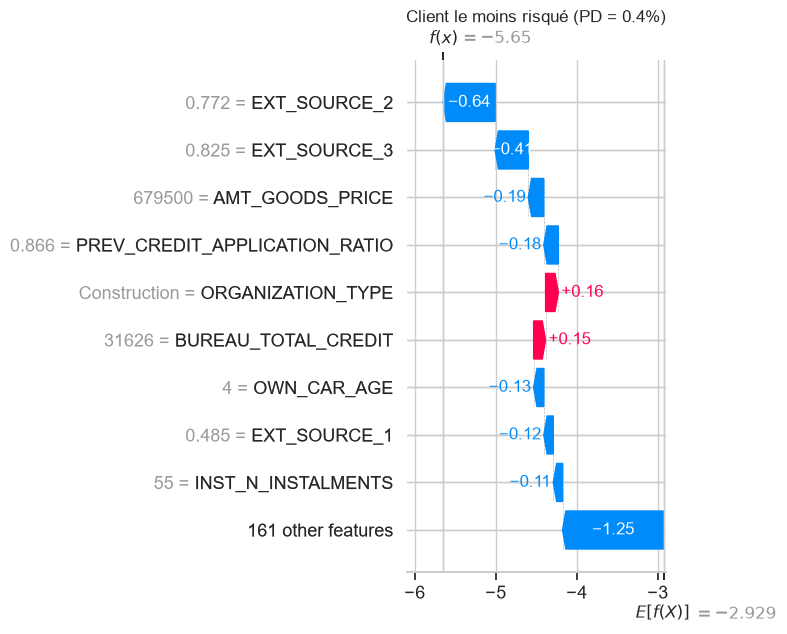

In [9]:
risk = 1 / (1 + np.exp(-contrib.sum(axis=1)))
worst, best = int(np.argmax(risk)), int(np.argmin(risk))

for idx, label in [(worst, "le plus risqué"), (best, "le moins risqué")]:
    print(f"Client {label} : probabilité de défaut {risk[idx]:.1%}")
    shap.plots.waterfall(explanation[idx], max_display=10, show=False)
    plt.title(f"Client {label} (PD = {risk[idx]:.1%})")
    plt.tight_layout(); plt.show()

**Lecture d'un graphique en cascade :** on part de la note moyenne `E[f(X)]` en bas ; chaque barre rouge ajoute du risque,
chaque barre bleue en retire ; on arrive à la note du client `f(x)` en haut.
On peut ainsi dire au client refusé : « votre demande a surtout été pénalisée par tel et tel élément ».

## 5. Conclusions

| | Scorecard | LightGBM |
|---|---|---|
| Performance (Gini test) | ≈ 0,52 | **≈ 0,58** |
| Variables | 19, sélectionnées | 170 brutes |
| Explicabilité | **native** (grille de points) | via SHAP |
| Acceptation par un régulateur | très facile | plus exigeante (documentation, SHAP, tests de stabilité) |

En pratique, beaucoup de banques gardent une scorecard pour la **décision réglementaire** et utilisent le boosting
comme **challenger**, ou pour des usages internes (prévention, recouvrement).

**Prochaine étape :** optimiser LightGBM (Optuna), vérifier la **calibration** des probabilités,
puis choisir un **seuil de décision** selon le coût d'un mauvais crédit.